<div style="padding: 20px 24px; border-radius: 12px; background: linear-gradient(110deg, #12304a, #187b8f); color: white; margin-bottom: 16px;">
  <div style="font-size: 0.78em; letter-spacing: 0.12em; text-transform: uppercase; opacity: 0.85;">HydroMT-SFINCS | Jakarta 02</div>
  <h1 style="color: white; margin: 8px 0 4px;">Update forcing conditions of a SFINCS model: Jakarta Bay 2026</h1>
  <div style="opacity: 0.95;">Add wind, simulation settings and the initial water level to the model of notebook 01.</div>
</div>


In this notebook, the model made in [01_build_quadtree](01_build_quadtree.ipynb) is updated, following the official example [2_update_forcing](https://deltares.github.io/hydromt_sfincs/latest/_examples/2_update_forcing.html) step by step.

In [1]:
from pathlib import Path

from hydromt_sfincs import SfincsModel
from hydromt import log

# [JAKARTA]
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
import numpy as np
import xarray as xr
import xugrid as xu
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from pyproj import Transformer

MSL = 1.12  # [JAKARTA] m EGM2008

C:\Users\ASUS\miniconda3\envs\asemelehoy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Steps followed in this notebook to update your SFINCS model:**
<ol>
<li> Initialize SfincsModel class, set data library, mode and root folder </li>
<li> Add spatially varying wind data [JAKARTA] </li>
<li> Set the simulation settings [JAKARTA] </li>
<li> Set the initial water level only in the sea [JAKARTA] </li>
<li> Save all files</li>
</ol> 

<div style="padding: 14px 18px; border-left: 4px solid #187b8f; background: #eaf6f8; border-radius: 6px; margin: 12px 1em 12px 0; width: calc(100% - 1em); box-sizing: border-box; color: #111111;">
  <strong><span style="font-size: 1.15em; margin-right: 4px;">&#128161;</span> [JAKARTA] Note</strong>
  <p style="margin: 8px 0 0;">The official example adds an upstream discharge, rainfall and infiltration. They are left out here because we first focus on the water level at the coast: the run with GEOGLOWS river discharge and GFS rainfall (<code>F:\asemelehoy\model\36_rek26_sungai_hujan_fes_stofs</code>) gave the same mean peak error at Muara Angke as the run without them (-6.91 vs -6.90 cm) and the same RMSE (4.77 vs 4.78 cm).</p>
</div>

Let's get started!

### 1. Initialize SfincsModel class, set data library, mode and root folder:

Before we can use all the tools provided by HydroMT-SFINCS, we have to initialize the SfincsModel instance. This creates a shortcut to all the model components and methods to read, write and create these components.

In contrast to the previous notebook, we now initialize the model in "append" mode: "r+", to make sure we can upgrade some of its components.

In [2]:
model_root = "../model/jakarta_2026_tanpa_struktur"  # [JAKARTA]

# Initialize logging, the lower the log level number, the more verbose (more info) the output
# NOTSET=0-9, DEBUG=10, INFO=20, WARNING=30, ERROR=40, CRITICAL=50
log.initialize_logging()
log.set_log_level(log_level=20)

# Add file handler to log to a file
log_file = Path(model_root) / "hydromt_sfincs.log"
logger = log._add_filehandler(log_file)

# Initialize SfincsModel Python class with our Jakarta data catalog  # [JAKARTA]
sf = SfincsModel(
    data_libs=["../data/data_catalog.yml"],  # [JAKARTA] specify which data libraries to use
    root=model_root,  # specify the root directory for the model
    mode="r+",  # specify the mode for opening the model (r=read only, r+=append, w=write,
    write_gis=True,  # specify whether to write GIS data
)

2026-11-27 09:24:49,178 - hydromt - log - INFO - HydroMT version: 1.4.1
2026-11-27 09:24:49,182 - hydromt.data_catalog.data_catalog - data_catalog - INFO - Parsing data catalog from ../data/data_catalog.yml
2026-11-27 09:24:49,546 - hydromt.model.model - model - INFO - Initializing sfincs model from hydromt_sfincs (v2.0.0).


### 2. Add spatially varying wind data [JAKARTA]

ERA5 hourly 10 m wind drives the wind set-up inside the bay. The STOFS surge at the boundary already contains the effect of the large-scale wind.

2026-11-27 09:24:50,706 - hydromt.data_catalog.sources.data_source - data_source - INFO - Reading era5_jakarta RasterDataset data from F:\asemelehoy\skema_terbaik\data\era5\era5_jakarta_2026-10.nc


(<Figure size 600x900 with 3 Axes>,
 array([<Axes: title={'center': 'SFINCS waterlevel forcing (bzs)'}, ylabel='waterlevel\n[m+ref]'>,
        <Axes: title={'center': 'SFINCS eastward wind forcing (wind10_u)'}, ylabel='mean eastward wind\n[m/s]'>,
        <Axes: title={'center': 'SFINCS northward wind forcing (wind10_v)'}, ylabel='mean northward wind\n[m/s]'>],
       dtype=object))

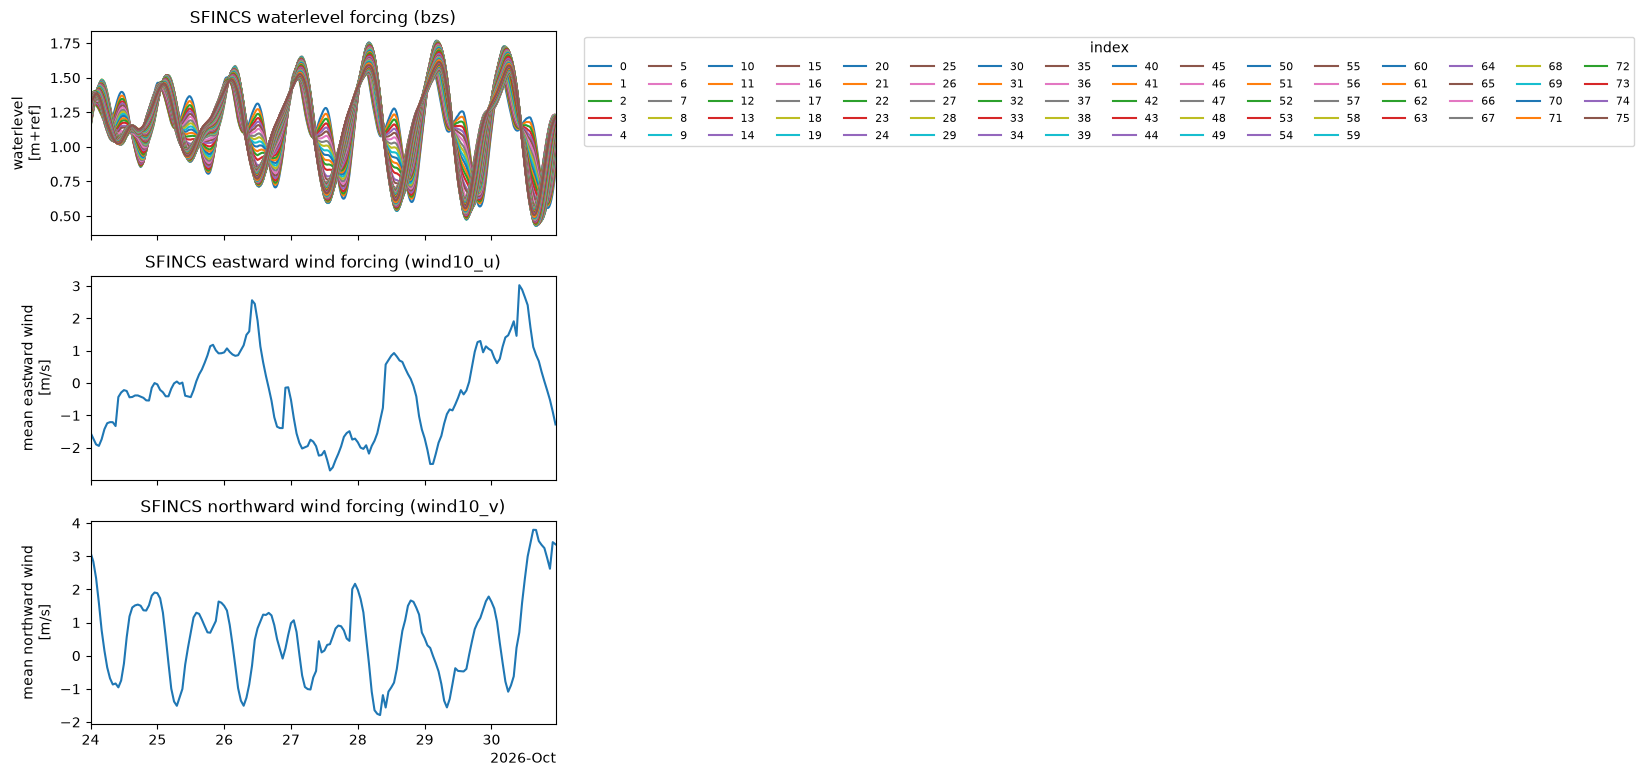

In [3]:
# hourly 10 m wind of ECMWF ERA5 for Jakarta Bay, 24-30 Oct 2026  # [JAKARTA]
sf.wind.create(wind="era5_jakarta")

sf.plot_forcing()

<div style="padding: 14px 18px; border-left: 4px solid #187b8f; background: #eaf6f8; border-radius: 6px; margin: 12px 1em 12px 0; width: calc(100% - 1em); box-sizing: border-box; color: #111111;">
  <strong><span style="font-size: 1.15em; margin-right: 4px;">&#128161;</span> [JAKARTA] Note</strong>
  <p style="margin: 8px 0 0;">Atmospheric pressure is not added (<code>baro = 0</code>, as in the best earlier run 32). The inverse barometer effect is already in the STOFS surge at the boundary, and inside the domain the ERA5 sea level pressure differs by only 1.1 hPa on average (at most 1.9 hPa) between 24 and 30 Oct, about 1 to 2 cm of water level.</p>
</div>

### 3. Set the simulation settings [JAKARTA]

The model starts on 24 Oct, four days before the sensor record (28 Oct 00:00 to 30 Oct 09:00 UTC), so the start-up has died out when we compare. During the first 6 hours (`tspinup`) the boundary water level is gradually raised from the initial level. Point output every 10 minutes matches the 10-minute sensor averages.

**Coriolis**: `coriolis = 1` is the default, but on a projected grid (UTM) SFINCS only applies it when `latitude` is given. All earlier runs in `F:\asemelehoy` had no Coriolis (their `sfincs.log` says *no Coriolis, as latitude is not specified in sfincs.inp*). Here `latitude` is the mean latitude of the active cells. For the meaning of each keyword see the [SFINCS manual](https://sfincs.readthedocs.io/en/latest/parameters.html).

In [4]:
# [JAKARTA] lintang rata-rata sel aktif (grid dalam UTM 48S)
x, y = sf.quadtree_grid.data.grid.face_coordinates.T
aktif = sf.quadtree_grid.data["mask"].values > 0
_, lat = Transformer.from_crs(32748, 4326, always_xy=True).transform(x[aktif], y[aktif])
latitude = round(float(lat.mean()), 2)
print("latitude:", latitude)

sf.config.update(
    {
        "tspinup": 21600,  # [s] 6 jam
        "dthisout": 600,  # [s] keluaran titik tiap 10 menit
        "dtmapout": 3600,  # [s] peta tiap jam
        "dtmaxout": 604800,  # [s] satu peta maksimum untuk seluruh simulasi
        "dtrstout": 21600,  # [s] file restart tiap 6 jam, untuk melanjutkan run yang terputus
        "advection": 1,
        "alpha": 0.5,
        "baro": 0,
        "latitude": latitude,  # Coriolis
    }
)

latitude: -5.86
2026-11-27 09:24:54,911 - hydromt.hydromt_sfincs.components.config.config - config - INFO - Updating 9 attributes in model config.


### 4. Set the initial water level only in the sea [JAKARTA]

With a uniform `zsini = MSL`, every closed depression below MSL behind the seawalls starts full of water that can never drain. An earlier fix with a drawn sea polygon (run 33) left some connected harbour and canal cells dry.

Here the sea is taken from the model itself: starting from the open boundary cells (mask = 2), we follow every cell face whose subgrid minimum level `uv_zmin` is below MSL, because water at MSL can flow through that face. All cells reached this way start at MSL; the rest starts dry (-9999). This is the still-water state that the model would reach with MSL at the boundary. The cell faces are numbered in the same order as in the subgrid builder of HydroMT-SFINCS (per cell: right neighbour(s), then upper neighbour(s)).

**Keep `zsini = MSL` next to the `inifile`.** HydroMT-SFINCS removes `zsini` when an initial water level file is made, so SFINCS uses its default `zsini = 0` (m EGM2008). SFINCS reads the initial field from the `inifile`, but during `tspinup` it ramps the boundary water level from `zsini` to the boundary data (`sfincs_boundaries.f90`). With `zsini = 0` the boundary starts 1.12 m below the sea inside the model, and the bay drains: in runs 33 and 43 the water level 2 to 3 hours after the start fell to -2.6 m EGM2008 at the offshore point and the bay kept oscillating for days. With `zsini = MSL` the ramp starts at the same level as the sea.

In [5]:
# [JAKARTA] titik u/v dengan urutan yang sama seperti hydromt_sfincs (subgrid_quadtree_builder.py)
grid = sf.quadtree_grid.data
sbg = sf.quadtree_subgrid.data
mu, mu1, mu2 = grid["mu"].values, grid["mu1"].values - 1, grid["mu2"].values - 1
nu, nu1, nu2 = grid["nu"].values, grid["nu1"].values - 1, grid["nu2"].values - 1
nm, nmu = [], []
for ic in range(mu.size):
    for tipe, n1, n2 in ((mu[ic], mu1[ic], mu2[ic]), (nu[ic], nu1[ic], nu2[ic])):
        for tetangga in ((n1,) if tipe <= 0 else (n1, n2)):
            if tetangga >= 0:
                nm.append(ic)
                nmu.append(tetangga)
nm, nmu = np.array(nm), np.array(nmu)
assert nm.size == sbg["uv_zmin"].size

# sel yang tersambung ke batas terbuka lewat sisi dengan uv_zmin < MSL
mask = grid["mask"].values
buka = sbg["uv_zmin"].values < MSL
graf = coo_matrix((np.ones(buka.sum()), (nm[buka], nmu[buka])), shape=(mask.size, mask.size))
_, label = connected_components(graf, directed=False)
laut = np.isin(label, label[mask == 2]) & (sbg["z_zmin"].values < MSL)

zs = xu.UgridDataArray(xr.DataArray(np.where(laut, MSL, -9999.0), dims=(grid.grid.face_dimension,), name="zs"), grid.grid)
zs.attrs.update(standard_name="initial water level", unit="m+ref")
sf.quadtree_grid.set(zs, name="zs")
sf.config.set("inifile", "sfincs_ini.nc")
sf.config.set("zsini", MSL)  # titik awal ramp batas selama tspinup (lihat markdown di atas)
print(f"sel aktif: {(mask > 0).sum()}, mulai basah (MSL): {laut.sum()}, mulai kering: {(mask > 0).sum() - laut.sum()}")

sel aktif: 120426, mulai basah (MSL): 109473, mulai kering: 10953


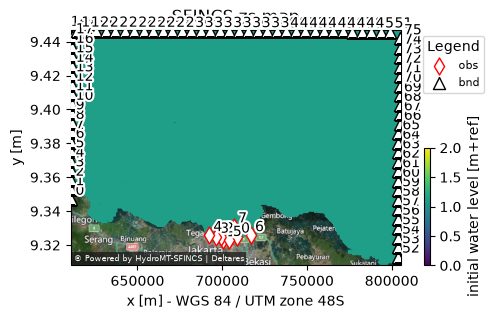

In [6]:
_ = sf.plot_basemap(
    variable=zs.where(zs > -9000), plot_bounds=False, bmap="sat", zoomlevel=9, vmin=0, vmax=2  # [JAKARTA]
)

### 5. Write all files

In [7]:
sf.write()
sf.quadtree_initial_conditions.write()  # [JAKARTA] sfincs_ini.nc

2026-11-27 09:25:16,631 - hydromt.hydromt_sfincs.writers - writers - INFO - No changes detected; skipping write to F:\asemelehoy\skema_terbaik\model\jakarta_2026_tanpa_struktur\sfincs_netbndbzsbzifile.nc


In [8]:
# [JAKARTA] exe lokal v2.4.0 belum bisa baca sfincs_ini.nc, jadi ditulis ulang sebagai biner float32
import xarray as xr
root = Path(model_root)
with xr.open_dataset(root / "sfincs_ini.nc") as ds:
    zs = ds["zs"].values.astype("float32")
zs.tofile(root / "sfincs_ini.bin")
print(zs.size, "sel, basah:", (zs > -9000).sum())

inp = root / "sfincs.inp"
teks = inp.read_text().replace("sfincs_ini.nc", "sfincs_ini.bin")
inp.write_text(teks)
print([b for b in teks.splitlines() if "ini" in b])

120426 sel, basah: 109473
['zsini                = 1.12', 'inifile              = sfincs_ini.bin']


Now your model has new boundary conditions, you can progress to the notebook: [Run SFINCS model](03_run_model.ipynb).